# Lab 07 — Improving HOG-Based Medical Image Classification Using a Genetic Algorithm
**Dataset:** BloodMNIST (medmnist)  
**Baseline:** HOG + RBF-SVM  
**Proposed:** GA-selected HOG features + RBF-SVM  

---

## Cell 1 — Install & Imports

In [3]:
!pip install medmnist -q

import numpy as np
import matplotlib.pyplot as plt
import time, random, warnings
warnings.filterwarnings("ignore")

from medmnist import BloodMNIST
import medmnist

from skimage.feature import hog
from skimage.transform import resize

from sklearn.svm import SVC, LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, balanced_accuracy_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, classification_report
)

np.random.seed(42)
random.seed(42)

print("medmnist version:", medmnist.__version__)
print("All imports OK ✓")

medmnist version: 3.0.2
All imports OK ✓


## Cell 2 — Load BloodMNIST

Train : (11959, 64, 64, 3)  |  Val : (1712, 64, 64, 3)  |  Test : (3421, 64, 64, 3)
Classes : [0 1 2 3 4 5 6 7]  (8 total)


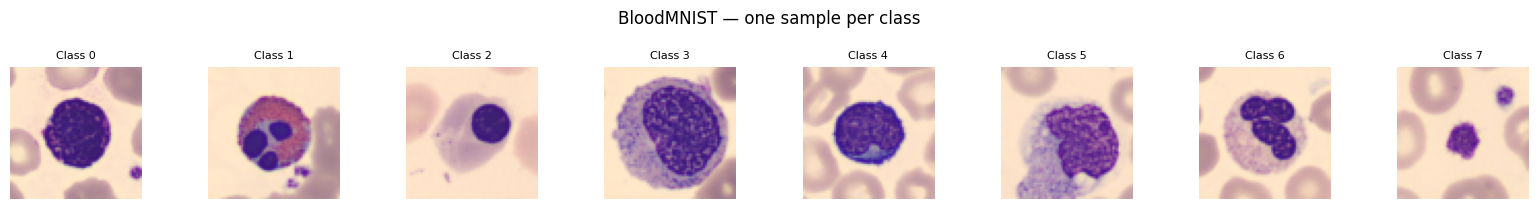

In [4]:
def load_split(split):
    ds = BloodMNIST(split=split, download=True, size=64)
    imgs, labels = [], []
    for img, label in ds:
        imgs.append(np.array(img))   # RGB (64,64,3)
        labels.append(int(label))
    return np.array(imgs), np.array(labels)

print("Downloading BloodMNIST ...")
X_train_raw, y_train = load_split("train")
X_val_raw,   y_val   = load_split("val")
X_test_raw,  y_test  = load_split("test")

print(f"Train : {X_train_raw.shape}  |  Val : {X_val_raw.shape}  |  Test : {X_test_raw.shape}")
print(f"Classes : {np.unique(y_train)}  ({len(np.unique(y_train))} total)")

# Quick preview
fig, axes = plt.subplots(1, 8, figsize=(16, 2))
for i, ax in enumerate(axes):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(X_train_raw[idx])
    ax.set_title(f"Class {i}", fontsize=8)
    ax.axis('off')
plt.suptitle("BloodMNIST — one sample per class", y=1.02)
plt.tight_layout()
plt.show()

## Cell 3 — HOG Feature Extraction

In [5]:
HOG_PARAMS = dict(
    orientations    = 9,
    pixels_per_cell = (8, 8),
    cells_per_block = (2, 2),
    block_norm      = 'L2-Hys',
    channel_axis    = -1       # RGB
)

def extract_hog(images):
    feats = []
    for img in images:
        h = hog(img, **HOG_PARAMS)
        feats.append(h)
    return np.array(feats)

print("Extracting HOG features ...")
t0 = time.time()
X_train_hog = extract_hog(X_train_raw)
X_val_hog   = extract_hog(X_val_raw)
X_test_hog  = extract_hog(X_test_raw)
hog_time = time.time() - t0

N_FEATURES = X_train_hog.shape[1]
print(f"HOG feature vector length : {N_FEATURES}")
print(f"Extraction time           : {hog_time:.1f}s")

# Standardise (fit on train only)
scaler    = StandardScaler()
X_train_s = scaler.fit_transform(X_train_hog)
X_val_s   = scaler.transform(X_val_hog)
X_test_s  = scaler.transform(X_test_hog)
print("Standardisation done ✓")

Extracting HOG features ...
HOG feature vector length : 1764
Extraction time           : 46.2s
Standardisation done ✓


## Cell 4 — Baseline: HOG + RBF-SVM

In [6]:
def compute_metrics(y_true, y_pred, label=""):
    acc  = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='macro', zero_division=0)
    rec  = recall_score(y_true, y_pred, average='macro', zero_division=0)
    f1m  = f1_score(y_true, y_pred, average='macro', zero_division=0)
    f1w  = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    bal  = balanced_accuracy_score(y_true, y_pred)
    kap  = cohen_kappa_score(y_true, y_pred)
    mcc  = matthews_corrcoef(y_true, y_pred)

    # Macro specificity (one-vs-rest)
    cm = confusion_matrix(y_true, y_pred)
    spec_list = []
    for i in range(len(cm)):
        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP
        TN = cm.sum() - TP - FP - FN
        spec_list.append(TN / (TN + FP + 1e-9))
    spec = np.mean(spec_list)

    print(f"\n{'='*50}")
    print(f"  {label}")
    print(f"{'='*50}")
    print(f"  Accuracy            : {acc*100:.2f}%")
    print(f"  Precision (Macro)   : {prec*100:.2f}%")
    print(f"  Recall (Macro)      : {rec*100:.2f}%")
    print(f"  Macro-F1            : {f1m*100:.2f}%")
    print(f"  Weighted-F1         : {f1w*100:.2f}%")
    print(f"  Balanced Accuracy   : {bal*100:.2f}%")
    print(f"  Specificity (Macro) : {spec*100:.2f}%")
    print(f"  Cohen's Kappa       : {kap:.4f}")
    print(f"  MCC                 : {mcc:.4f}")
    return dict(acc=acc, prec=prec, rec=rec, f1m=f1m,
                f1w=f1w, bal=bal, spec=spec, kap=kap, mcc=mcc)

print("Training Baseline SVM on ALL HOG features ...")
t0 = time.time()
baseline_svm = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
baseline_svm.fit(X_train_s, y_train)
baseline_train_time = time.time() - t0

t0 = time.time()
y_pred_base = baseline_svm.predict(X_test_s)
baseline_infer_time = time.time() - t0

base_results = compute_metrics(y_test, y_pred_base, "Baseline HOG+SVM (Test Set)")
print(f"  Train time          : {baseline_train_time:.1f}s")
print(f"  Inference time      : {baseline_infer_time:.3f}s")

Training Baseline SVM on ALL HOG features ...

  Baseline HOG+SVM (Test Set)
  Accuracy            : 81.18%
  Precision (Macro)   : 81.88%
  Recall (Macro)      : 79.80%
  Macro-F1            : 80.71%
  Weighted-F1         : 81.14%
  Balanced Accuracy   : 79.80%
  Specificity (Macro) : 97.22%
  Cohen's Kappa       : 0.7794
  MCC                 : 0.7797
  Train time          : 124.6s
  Inference time      : 63.961s


## Cell 5 — Genetic Algorithm

In [7]:
# ── GA Hyper-parameters ──────────────────────────────────
LAMBDA = 0.05   # penalty weight for feature ratio in fitness

# Subsample the dataset used for fitness evaluation to speed things up significantly!
# Training on a 5% random sample of the training set is plenty for assessing feature utility.
np.random.seed(42)
fit_sample_size = int(0.05 * len(X_train_s))
fit_indices = np.random.choice(len(X_train_s), fit_sample_size, replace=False)
X_train_s_sub = X_train_s[fit_indices]
y_train_sub = y_train[fit_indices]

# Simple cache to avoid evaluating the same chromosome twice
_fitness_cache = {}

def fitness(mask):
    """fitness = val_macro_F1 - LAMBDA * feature_ratio"""
    # Convert mask to a tuple so it can be hashed for caching
    mask_tuple = tuple(mask)
    if mask_tuple in _fitness_cache:
        return _fitness_cache[mask_tuple]

    idx = np.where(mask)[0]
    if len(idx) == 0:
        return 0.0

    # Use the downsampled training subset for extremely fast training
    Xtr = X_train_s_sub[:, idx]
    Xvl = X_val_s[:, idx]

    # dual=False + max_iter=100 + tol=1e-3 yields incredibly fast training times
    clf = LinearSVC(C=1.0, max_iter=100, tol=1e-3, dual=False, random_state=42)
    try:
        clf.fit(Xtr, y_train_sub)
        pred  = clf.predict(Xvl)
        f1    = f1_score(y_val, pred, average='macro', zero_division=0)
        ratio = len(idx) / N_FEATURES
        score = f1 - LAMBDA * ratio
        _fitness_cache[mask_tuple] = score
        return score
    except Exception:
        _fitness_cache[mask_tuple] = 0.0
        return 0.0

# ── GA operators ─────────────────────────────────────────
def init_population(pop_size, n_feat, init_ratio=0.5):
    return [(np.random.rand(n_feat) < init_ratio).astype(int)
            for _ in range(pop_size)]

def tournament_select(pop, scores, k=3):
    idx  = random.sample(range(len(pop)), k)
    best = max(idx, key=lambda i: scores[i])
    return pop[best].copy()

def one_point_crossover(p1, p2):
    pt = random.randint(1, len(p1)-1)
    return (np.concatenate([p1[:pt], p2[pt:]]),
            np.concatenate([p2[:pt], p1[pt:]]))

def mutate(mask, mut_prob):
    flip = np.random.rand(len(mask)) < mut_prob
    mask = mask.copy()
    mask[flip] = 1 - mask[flip]
    return mask

# ── Main GA loop ─────────────────────────────────────────
def run_ga(pop_size=30, n_gen=20, mut_prob=0.01,
           cx_prob=0.8, elitism=2, label="GA"):
    print(f"\n{'='*60}")
    print(f"  {label}")
    print(f"  pop_size={pop_size}  generations={n_gen}  mut_prob={mut_prob}")
    print(f"{'='*60}")

    pop        = init_population(pop_size, N_FEATURES)
    best_mask  = None
    best_score = -np.inf
    gen_best   = []
    gen_avg    = []

    for gen in range(n_gen):
        scores = [fitness(m) for m in pop]
        gen_best.append(max(scores))
        gen_avg.append(np.mean(scores))

        top_idx = int(np.argmax(scores))
        if scores[top_idx] > best_score:
            best_score = scores[top_idx]
            best_mask  = pop[top_idx].copy()

        # Elitism: carry top individuals unchanged
        elite_idxs = np.argsort(scores)[-elitism:]
        new_pop    = [pop[i].copy() for i in elite_idxs]

        while len(new_pop) < pop_size:
            p1 = tournament_select(pop, scores)
            p2 = tournament_select(pop, scores)
            if random.random() < cx_prob:
                c1, c2 = one_point_crossover(p1, p2)
            else:
                c1, c2 = p1.copy(), p2.copy()
            new_pop.append(mutate(c1, mut_prob))
            if len(new_pop) < pop_size:
                new_pop.append(mutate(c2, mut_prob))

        pop = new_pop
        print(f"  Gen {gen+1:02d}/{n_gen}  "
              f"best_fit={gen_best[-1]:.4f}  "
              f"avg_fit={gen_avg[-1]:.4f}  "
              f"features_selected={best_mask.sum()}/{N_FEATURES}")

    return best_mask, gen_best, gen_avg

# Clear cache before runs
_fitness_cache.clear()

# ── Run GA Config-1 ───────────────────────────────────────
t_ga1 = time.time()
mask1, hist1_best, hist1_avg = run_ga(
    pop_size=30, n_gen=20, mut_prob=0.01,
    label="GA Config-1  (pop=30, mut=0.01)")
ga1_time = time.time() - t_ga1

# ── Run GA Config-2 ───────────────────────────────────────
t_ga2 = time.time()
mask2, hist2_best, hist2_avg = run_ga(
    pop_size=50, n_gen=20, mut_prob=0.03,
    label="GA Config-2  (pop=50, mut=0.03)")
ga2_time = time.time() - t_ga2

print(f"\nGA-1 selected {mask1.sum()} / {N_FEATURES} features  (time: {ga1_time:.1f}s)")
print(f"GA-2 selected {mask2.sum()} / {N_FEATURES} features  (time: {ga2_time:.1f}s)")


  GA Config-1  (pop=30, mut=0.01)
  pop_size=30  generations=20  mut_prob=0.01
  Gen 01/20  best_fit=0.4251  avg_fit=0.4069  features_selected=888/1764
  Gen 02/20  best_fit=0.4329  avg_fit=0.4164  features_selected=867/1764
  Gen 03/20  best_fit=0.4332  avg_fit=0.4205  features_selected=849/1764
  Gen 04/20  best_fit=0.4392  avg_fit=0.4242  features_selected=850/1764
  Gen 05/20  best_fit=0.4392  avg_fit=0.4262  features_selected=850/1764
  Gen 06/20  best_fit=0.4404  avg_fit=0.4275  features_selected=864/1764
  Gen 07/20  best_fit=0.4476  avg_fit=0.4285  features_selected=876/1764
  Gen 08/20  best_fit=0.4476  avg_fit=0.4319  features_selected=876/1764
  Gen 09/20  best_fit=0.4476  avg_fit=0.4354  features_selected=876/1764
  Gen 10/20  best_fit=0.4479  avg_fit=0.4379  features_selected=871/1764
  Gen 11/20  best_fit=0.4499  avg_fit=0.4374  features_selected=886/1764
  Gen 12/20  best_fit=0.4499  avg_fit=0.4410  features_selected=886/1764
  Gen 13/20  best_fit=0.4575  avg_fit=0.4403

## Cell 6 — Train Final RBF-SVM on GA-Selected Features

In [12]:
def train_final_svm(mask, label=""):
    idx = np.where(mask)[0]
    Xtr = X_train_s[:, idx]
    Xte = X_test_s[:, idx]

    t0  = time.time()
    clf = SVC(kernel='rbf', C=10, gamma='scale', random_state=42)
    clf.fit(Xtr, y_train)
    tr_time = time.time() - t0

    t0   = time.time()
    pred = clf.predict(Xte)
    inf_time = time.time() - t0

    res = compute_metrics(y_test, pred, label)
    print(f"  Train time          : {tr_time:.1f}s")
    print(f"  Inference time      : {inf_time:.3f}s")
    return res, tr_time, inf_time, clf

print("\n>>> Final evaluation on TEST SET (RBF-SVM on selected features)")
ga1_results, ga1_tr, ga1_inf, clf_ga1 = train_final_svm(
    mask1, "GA Config-1  HOG+SVM (Test Set)")
ga2_results, ga2_tr, ga2_inf, clf_ga2 = train_final_svm(
    mask2, "GA Config-2  HOG+SVM (Test Set)")


>>> Final evaluation on TEST SET (RBF-SVM on selected features)

  GA Config-1  HOG+SVM (Test Set)
  Accuracy            : 80.42%
  Precision (Macro)   : 81.14%
  Recall (Macro)      : 78.92%
  Macro-F1            : 79.88%
  Weighted-F1         : 80.37%
  Balanced Accuracy   : 78.92%
  Specificity (Macro) : 97.11%
  Cohen's Kappa       : 0.7704
  MCC                 : 0.7708
  Train time          : 59.2s
  Inference time      : 31.507s

  GA Config-2  HOG+SVM (Test Set)
  Accuracy            : 80.30%
  Precision (Macro)   : 80.72%
  Recall (Macro)      : 78.84%
  Macro-F1            : 79.65%
  Weighted-F1         : 80.24%
  Balanced Accuracy   : 78.84%
  Specificity (Macro) : 97.10%
  Cohen's Kappa       : 0.7691
  MCC                 : 0.7694
  Train time          : 51.4s
  Inference time      : 33.454s


## Cell 7 — Summary Tables

In [ ]:
def fmt(v, pct=True):
    return f"{v*100:.2f}%" if pct else f"{v:.4f}"

def improvement(base, proposed, pct=True):
    diff = proposed - base
    sign = "+" if diff >= 0 else ""
    if pct:
        return f"{sign}{diff*100:.2f}%"
    return f"{sign}{diff:.4f}"

print("\n" + "="*80)
print("TABLE 2 — Main Performance Comparison (Test Set)")
print("="*80)
print(f"{'Metric':<28} {'Baseline':>12} {'GA-1 (↑/↓)':>16} {'GA-2 (↑/↓)':>16}")
print("-"*80)

rows = [
    ("Accuracy (%)",         'acc',  True),
    ("Precision Macro (%)",  'prec', True),
    ("Recall Macro (%)",     'rec',  True),
    ("Macro-F1 (%)",         'f1m',  True),
    ("Weighted-F1 (%)",      'f1w',  True),
    ("Balanced Accuracy (%)", 'bal', True),
    ("Specificity Macro (%)", 'spec',True),
    ("Cohen's Kappa",         'kap', False),
    ("MCC",                   'mcc', False),
]
for name, key, pct in rows:
    b  = base_results[key]
    g1 = ga1_results[key]
    g2 = ga2_results[key]
    g1_str = f"{fmt(g1,pct)} ({improvement(b,g1,pct)})"
    g2_str = f"{fmt(g2,pct)} ({improvement(b,g2,pct)})"
    print(f"{name:<28} {fmt(b,pct):>12} {g1_str:>16} {g2_str:>16}")

print("\n" + "="*80)
print("TABLE 3 — Feature Count and Computational Time")
print("="*80)
print(f"{'Metric':<38} {'Baseline':>10} {'GA-1':>10} {'GA-2':>10}")
print("-"*80)
r1 = (1 - mask1.sum()/N_FEATURES)*100
r2 = (1 - mask2.sum()/N_FEATURES)*100
print(f"{'Total HOG features':<38} {N_FEATURES:>10} {N_FEATURES:>10} {N_FEATURES:>10}")
print(f"{'Features selected':<38} {N_FEATURES:>10} {mask1.sum():>10} {mask2.sum():>10}")
print(f"{'Feature reduction (%)':<38} {'0.00%':>10} {r1:>9.2f}% {r2:>9.2f}%")
print(f"{'GA search time (s)':<38} {'N/A':>10} {ga1_time:>10.1f} {ga2_time:>10.1f}")
print(f"{'SVM train time (s)':<38} {baseline_train_time:>10.1f} {ga1_tr:>10.1f} {ga2_tr:>10.1f}")
print(f"{'SVM inference time (s)':<38} {baseline_infer_time:>10.3f} {ga1_inf:>10.3f} {ga2_inf:>10.3f}")

## Cell 8 — Plots

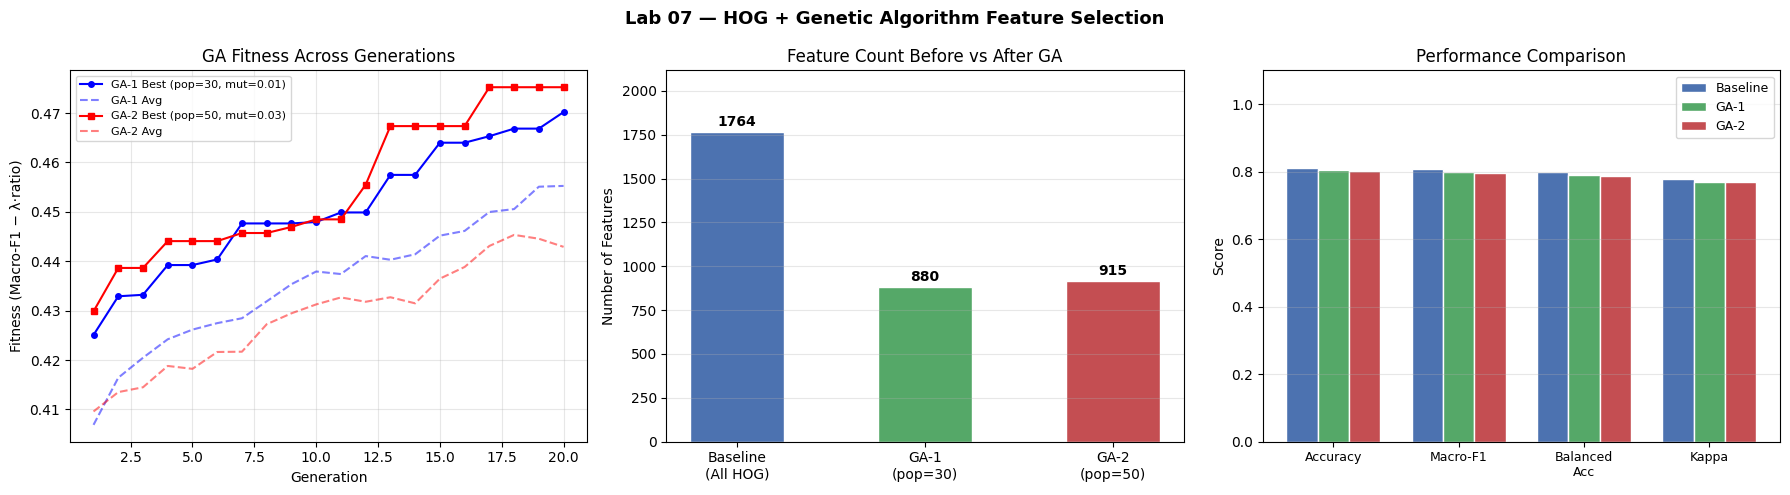

Figure saved → lab07_results.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Lab 07 — HOG + Genetic Algorithm Feature Selection",
             fontsize=13, fontweight='bold')

# ── Plot 1: GA fitness curves ─────────────────────────────
ax   = axes[0]
gens = range(1, len(hist1_best)+1)
ax.plot(gens, hist1_best, 'b-o', ms=4, label='GA-1 Best (pop=30, mut=0.01)')
ax.plot(gens, hist1_avg,  'b--',  ms=3, alpha=0.5, label='GA-1 Avg')
ax.plot(gens, hist2_best, 'r-s', ms=4, label='GA-2 Best (pop=50, mut=0.03)')
ax.plot(gens, hist2_avg,  'r--',  ms=3, alpha=0.5, label='GA-2 Avg')
ax.set_xlabel("Generation")
ax.set_ylabel("Fitness (Macro-F1 − λ·ratio)")
ax.set_title("GA Fitness Across Generations")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

# ── Plot 2: Feature count ─────────────────────────────────
ax      = axes[1]
models  = ['Baseline\n(All HOG)', 'GA-1\n(pop=30)', 'GA-2\n(pop=50)']
n_feats = [N_FEATURES, int(mask1.sum()), int(mask2.sum())]
colors  = ['#4c72b0', '#55a868', '#c44e52']
bars    = ax.bar(models, n_feats, color=colors, edgecolor='white', width=0.5)
for bar, val in zip(bars, n_feats):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + N_FEATURES*0.01,
            str(val), ha='center', va='bottom',
            fontsize=10, fontweight='bold')
ax.set_ylabel("Number of Features")
ax.set_title("Feature Count Before vs After GA")
ax.set_ylim(0, N_FEATURES * 1.2)
ax.grid(axis='y', alpha=0.3)

# ── Plot 3: Metric comparison bar chart ───────────────────
ax           = axes[2]
metric_names = ['Accuracy', 'Macro-F1', 'Balanced\nAcc', 'Kappa']
base_vals    = [base_results['acc'], base_results['f1m'],
                base_results['bal'], base_results['kap']]
ga1_vals     = [ga1_results['acc'],  ga1_results['f1m'],
                ga1_results['bal'],  ga1_results['kap']]
ga2_vals     = [ga2_results['acc'],  ga2_results['f1m'],
                ga2_results['bal'],  ga2_results['kap']]
x  = np.arange(len(metric_names))
w  = 0.25
ax.bar(x - w, base_vals, w, label='Baseline', color='#4c72b0', edgecolor='white')
ax.bar(x,     ga1_vals,  w, label='GA-1',     color='#55a868', edgecolor='white')
ax.bar(x + w, ga2_vals,  w, label='GA-2',     color='#c44e52', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(metric_names, fontsize=9)
ax.set_ylabel("Score")
ax.set_title("Performance Comparison")
ax.legend(fontsize=9)
ax.set_ylim(0, 1.1)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig("lab07_results.png", dpi=150, bbox_inches='tight')
plt.show()
print("Figure saved → lab07_results.png")

## Cell 9 — Per-Class Classification Report (Best GA)


=== Per-Class Report — GA Config-1 (Best GA, Test Set) ===
              precision    recall  f1-score   support

    Basophil     0.7991    0.7172    0.7559       244
  Eosinophil     0.7500    0.8173    0.7822       624
Erythroblast     0.8724    0.8135    0.8419       311
          IG     0.6467    0.6891    0.6672       579
  Lymphocyte     0.8973    0.8272    0.8608       243
    Monocyte     0.6987    0.5880    0.6386       284
  Neutrophil     0.8765    0.8739    0.8752       666
    Platelet     0.9508    0.9872    0.9687       470

    accuracy                         0.8042      3421
   macro avg     0.8114    0.7892    0.7988      3421
weighted avg     0.8056    0.8042    0.8037      3421



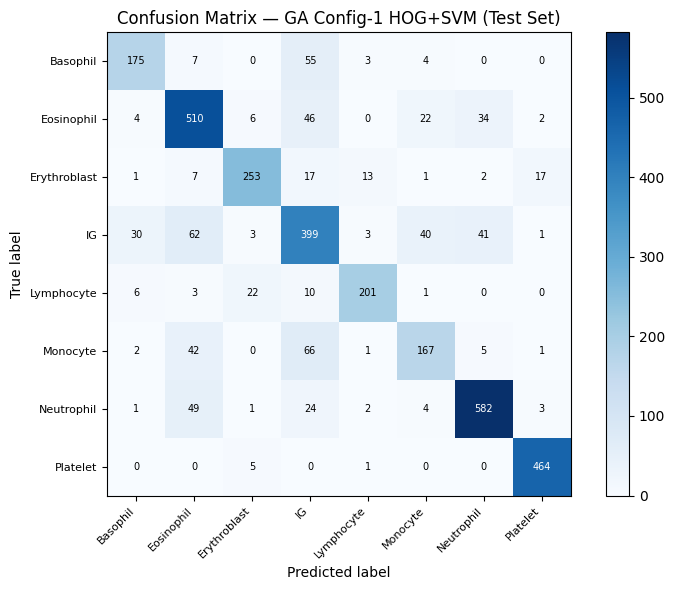

Confusion matrix saved → lab07_confusion.png

✅  Lab 07 complete. All tables, plots, and reports generated.


In [11]:
CLASS_NAMES = [
    'Basophil', 'Eosinophil', 'Erythroblast',
    'IG', 'Lymphocyte', 'Monocyte',
    'Neutrophil', 'Platelet'
]

if ga1_results['f1m'] >= ga2_results['f1m']:
    best_mask, best_clf, best_label = mask1, clf_ga1, "GA Config-1"
else:
    best_mask, best_clf, best_label = mask2, clf_ga2, "GA Config-2"

idx          = np.where(best_mask)[0]
y_pred_best  = best_clf.predict(X_test_s[:, idx])

print(f"\n=== Per-Class Report — {best_label} (Best GA, Test Set) ===")
print(classification_report(y_test, y_pred_best,
                             target_names=CLASS_NAMES, digits=4))

# Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred_best)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm, interpolation='nearest', cmap='Blues')
plt.colorbar(im, ax=ax)
tick_marks = np.arange(len(CLASS_NAMES))
ax.set_xticks(tick_marks); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha='right', fontsize=8)
ax.set_yticks(tick_marks); ax.set_yticklabels(CLASS_NAMES, fontsize=8)
thresh = cm.max() / 2
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i,j]), ha='center', va='center',
                fontsize=7, color='white' if cm[i,j] > thresh else 'black')
ax.set_ylabel('True label')
ax.set_xlabel('Predicted label')
ax.set_title(f'Confusion Matrix — {best_label} HOG+SVM (Test Set)')
plt.tight_layout()
plt.savefig("lab07_confusion.png", dpi=150, bbox_inches='tight')
plt.show()
print("Confusion matrix saved → lab07_confusion.png")

print("\n✅  Lab 07 complete. All tables, plots, and reports generated.")